In [2]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import os
import pandas as pd
from scipy.optimize import minimize
import functools
from scipy.linalg import lstsq

In [3]:
def str2float(string):
    minutes = float(string.split('m')[0])
    seconds = float(string.split('m')[1].split('s')[0])
    return minutes + seconds/60

def get_times(path):
    times_init = []
    times_cmap = []
    for mapid in sorted(os.listdir(path)):
        times_init.append(str2float(np.loadtxt(path+mapid+'/time_init.dat', skiprows=1, dtype=str)[0,1]))
        times_cmap.append(str2float(np.loadtxt(path+mapid+'/time_cmap.dat', skiprows=1, dtype=str)[0,1]))
    times_init = np.asarray(times_init)
    times_cmap = np.asarray(times_cmap)
    return times_init, times_cmap, times_init+times_cmap

In [4]:
# get no. of stars per map
nstars = []
for mapid in sorted(os.listdir('/home/favio/cmaps/cmaps_v1/')):
    if os.path.isdir('/home/favio/cmaps/cmaps_v1/'+mapid):
        nstars.append(np.loadtxt('/home/favio/cmaps/cmaps_v1/'+mapid+'/lens_pos.dat', usecols=0).size)
nstars = np.asarray(nstars)

# get time for single thread
time_n1 = []
for mapid in sorted(os.listdir('/home/favio/cmaps/cmaps_v1/')):
    if os.path.isdir('/home/favio/cmaps/cmaps_v1/'+mapid):
        time_n1.append(str2float(np.loadtxt('/home/favio/cmaps/cmaps_v1/'+mapid+'/time.dat', skiprows=1, dtype=str)[0,1]))
time_n1 = np.asarray(time_n1)

# get time for n threads
time_init_n2, time_cmap_n2, time_n2 = get_times('/home/favio/cmaps/cmaps_v2/')
time_init_n4, time_cmap_n4, time_n4 = get_times('/home/favio/cmaps/cmaps_v4/')
time_init_n6, time_cmap_n6, time_n6 = get_times('/home/favio/cmaps/cmaps_v6/')
time_init_n8, time_cmap_n8, time_n8 = get_times('/home/favio/cmaps/cmaps_v8/')

In [5]:
def model(nstars, nthreads):
                    # 95% confidence bounds
    p00 = -5.714    # (-7.565, -3.863)
    p10 = 1.173     # (0.8661, 1.48)
    p01 = 0.008415  # (0.006906, 0.009923)
    p11 = -0.001764 # (-0.001933, -0.001595)
    p02 = 1.092e-06 # (9.39e-07, 1.244e-06)
    
    return p00 + p10*nthreads + p01*nstars + p11*nthreads*nstars + p02*nstars**2

In [10]:
model(500, 8)

1.0945000000000005

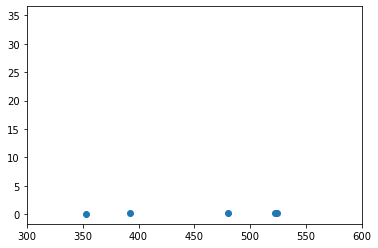

In [8]:
plt.xlim([300,600])
plt.scatter(nstars, time_cmap_n8)

In [98]:
nstars_grid, nthreads_grid = np.meshgrid(np.linspace(100, 40000, 100), np.linspace(2, 20, 35))

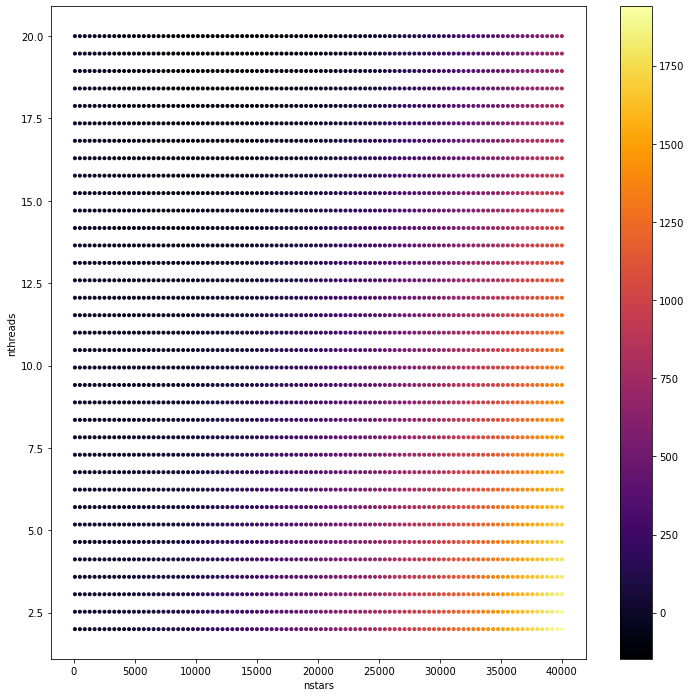

In [103]:
plt.figure(figsize=(12,12))
plt.xlabel('nstars')
plt.ylabel('nthreads')
plt.scatter(nstars_grid, nthreads_grid, c=model(nstars_grid,nthreads_grid), marker='.', cmap='inferno')
plt.colorbar()

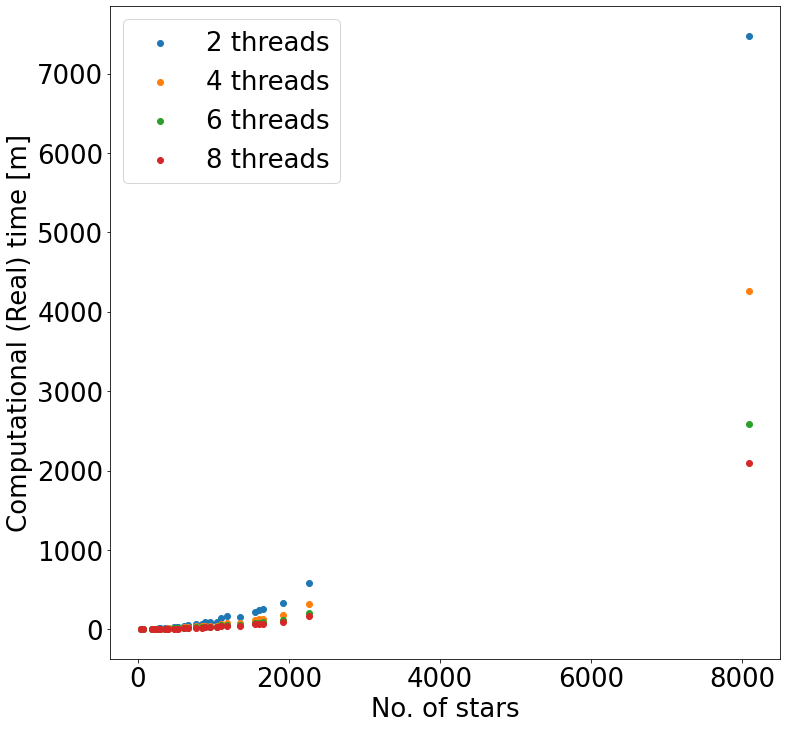

In [236]:
plt.rcParams.update({'font.size': 26})
plt.figure(figsize=(12,12))
plt.xlabel('No. of stars')
plt.ylabel('Computational (Real) time [m]')

plt.scatter(nstars, time_cmap_n2, label='2 threads')
plt.scatter(nstars, time_cmap_n4, label='4 threads')
plt.scatter(nstars, time_cmap_n6, label='6 threads')
plt.scatter(nstars, time_cmap_n8, label='8 threads')

plt.legend()

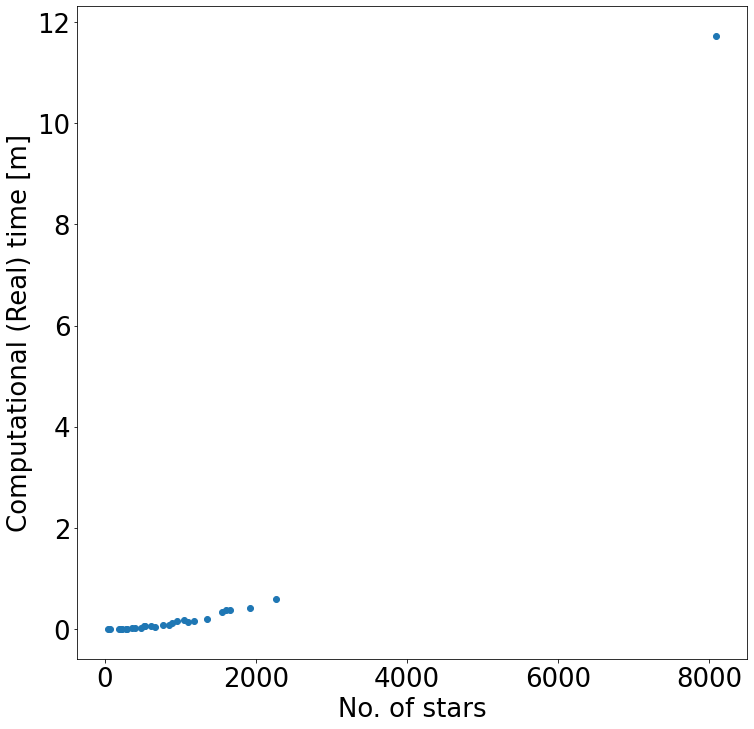

In [32]:
plt.rcParams.update({'font.size': 26})
plt.figure(figsize=(12,12))
plt.xlabel('No. of stars')
plt.ylabel('Computational (Real) time [m]')

plt.scatter(nstars, time_init_n2)

In [3]:
nstars         = []
time_v1        = []
time_v2_init   = []
time_v2_cmap   = []

for dir in sorted(os.listdir('/home/favio/cmaps/')):
    if os.path.isfile('/home/favio/cmaps/'+dir+'/time.dat') and os.stat('/home/favio/cmaps/'+dir+'/time.dat').st_size != 0 and dir != '35446':
        nstars.append(np.loadtxt('/home/favio/cmaps/'+dir+'/lens_pos.dat', usecols=0).size)
        time_v1.append(str2float(np.loadtxt('/home/favio/cmaps/'+dir+'/time.dat', skiprows=1, dtype=str)[0,1]))
        time_v2_init.append(str2float(np.loadtxt('/home/favio/cmaps_v2/'+dir+'/time_init.dat', skiprows=1, dtype=str)[0,1]))
        time_v2_cmap.append(str2float(np.loadtxt('/home/favio/cmaps_v2/'+dir+'/time_cmap.dat', skiprows=1, dtype=str)[0,1]))
        
time_v2 = []
for i in range(len(time_v2_init)):
    time_v2.append(time_v2_init[i] + time_v2_cmap[i])
    
nstars = np.array(nstars)
time_v1 = np.array(time_v1)
time_v2_init = np.array(time_v2_init)
time_v2_cmap = np.array(time_v2_cmap)
time_v2 = np.array(time_v2)

In [4]:
model_v1 = np.polyfit(nstars, time_v1, deg=2)
model_v2_init = np.polyfit(nstars, time_v2_init, deg=2)
model_v2_cmap = np.polyfit(nstars, time_v2_cmap, deg=2)
model_v2 = np.polyfit(nstars, time_v2, deg=2)

In [5]:
nstars_test = np.loadtxt('/home/favio/cmaps/35446/lens_pos.dat', usecols=0).size
time_v1_test = str2float(np.loadtxt('/home/favio/cmaps/35446/time.dat', skiprows=1, dtype=str)[0,1])
time_v2_init_test = str2float(np.loadtxt('/home/favio/cmaps_v2/35446/time_init.dat', skiprows=1, dtype=str)[0,1])
time_v2_cmap_test = str2float(np.loadtxt('/home/favio/cmaps_v2/35446/time_cmap.dat', skiprows=1, dtype=str)[0,1])
time_v2_test = time_v2_init_test + time_v2_cmap_test

In [6]:
time_v1_test

259.4333

In [7]:
np.polyval(model_v1, nstars_test)

244.02085530005456

In [8]:
time_v2_test

46.56698333333334

In [13]:
np.polyval(model_v2, 40000)

1015.4117036061928

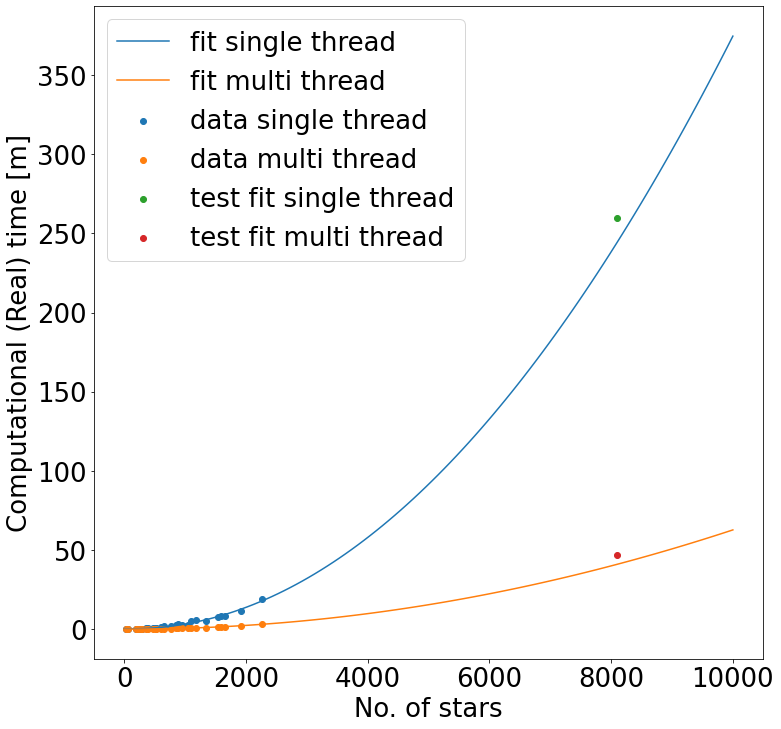

In [12]:
plt.rcParams.update({'font.size': 26})
plt.figure(figsize=(12,12))
plt.xlabel('No. of stars')
plt.ylabel('Computational (Real) time [m]')
nstars_fit = np.linspace(0, 10000, 100)

plt.plot(nstars_fit, np.polyval(model_v1, nstars_fit), label='fit single thread')
plt.scatter(nstars, time_v1, label='data single thread')

plt.plot(nstars_fit, np.polyval(model_v2, nstars_fit), label='fit multi thread')
plt.scatter(nstars, time_v2, label='data multi thread')

plt.scatter(nstars_test, time_v1_test, label='test fit single thread')
plt.scatter(nstars_test, time_v2_test, label='test fit multi thread')

plt.legend();

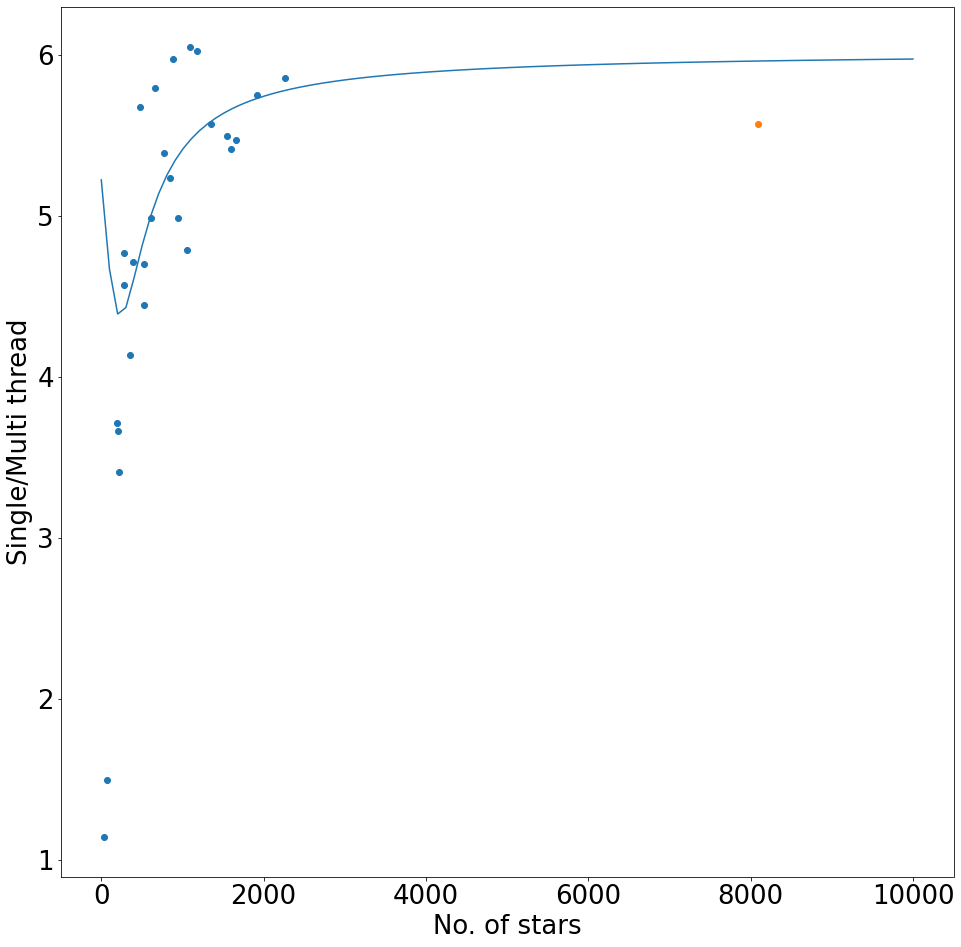

In [11]:
plt.rcParams.update({'font.size': 26})
plt.figure(figsize=(16,16))
plt.xlabel('No. of stars')
plt.ylabel('Single/Multi thread')
nstars_fit = np.linspace(0, 10000, 100)
plt.plot(nstars_fit, np.polyval(model_v1, nstars_fit)/np.polyval(model_v2, nstars_fit), label='fit')
plt.scatter(nstars, time_v1/time_v2, label='data')
plt.scatter(nstars_test, time_v1_test/time_v2_test, label='test')